# m01 - Baseline Models and the Cross-Validation Leakage Gap

**Task.** Predict each crop's GAEZ suitability index (0-10,000) for every 1 km cell from the 14 physical drivers
(5 climate, 7 soil, 2 terrain variables). Ten crops x six model families.

**Target.** GAEZ v5 at 30 arc-seconds (~1 km, `scripts/preprocessing/12_gaez_v5_1km.ipynb`), so every cell has its
own value; the 9,129 cells with a value for all ten crops are used (GAEZ leaves the rest as no cropland or open water).
The first round of experiments used the 5 arc-minute product (~9 km, only 164 distinct values over Banten); m13
compares the two targets.

**Why the CV scheme matters.** Neighbouring cells have almost the same climate, soil and suitability, so a random
K-fold tests on cells whose near-twins sit in the training set. Three schemes are compared (5 folds, 2 repeats with
different fold assignments):

| scheme | what is held out together |
| --- | --- |
| `random` | single 1 km cells (the naive default) |
| `block10` | 10 x 10 km blocks |
| `pixel` | whole ~9 km pixels of the GAEZ 5 arc-minute grid (~80 cells each) |

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

In [2]:
df = E.load_table()
print(f"{len(df)} cells, {df['pix'].nunique()} ~9 km GAEZ pixels (the blocks of the pixel scheme) cover them "
      f"(median {df.groupby('pix').size().median():.0f} cells per pixel)")

MODELS = ["dummy", "ridge", "knn", "et", "hgb", "xgb"]
SCHEMES = ["random", "block10", "pixel"]
FEATURES = E.feature_columns()           # climate + soil + terrain
print(len(FEATURES), "features:", FEATURES)

targets = {c: df[E.target_col(c)].to_numpy() for c in E.CROPS}   # GAEZ v5 at 1 km (E.TARGET_RES)

9129 cells, 163 ~9 km GAEZ pixels (the blocks of the pixel scheme) cover them (median 77 cells per pixel)
14 features: ['bio1_temp_mean_c', 'bio12_precip_annual_mm', 'bio15_precip_seasonality', 'chirps_annual_mean_mm', 'chirps_annual_std_mm', 'soil_ph', 'soil_soc', 'soil_nitrogen', 'soil_clay_pct', 'soil_sand_pct', 'soil_cec', 'soil_bulk_density', 'elevation_mean_m', 'slope_mean_deg']


## 1. Run the grid
Every model sees exactly the same folds, so differences between models are not fold luck.

In [3]:
res, oof = E.run_grid(df, targets, MODELS, SCHEMES, n_repeats=2, keep_oof=True)
E.save_table(res, "m01_baselines_raw")
res.head()

360 tasks (6 models x 10 targets x 3 schemes x 2 repeats), 14 features


done in 81 s


,target,model,scheme,repeat,fit_seconds,n_train_mean,r2,rmse,mae,spearman
0,rice,dummy,random,0,0.015433,7303.2,-0.000095,2461.677674,2072.582484,-0.012393
1,rice,dummy,random,1,0.015470,7303.2,-0.000279,2461.904387,2072.705589,-0.019315
2,rice,dummy,block10,0,0.012676,7303.2,-0.021581,2487.980627,2094.941200,-0.126183
3,rice,dummy,block10,1,0.012186,7303.2,-0.028394,2496.263505,2100.035584,-0.201795
4,rice,dummy,pixel,0,0.011706,7303.2,-0.007693,2471.011009,2082.729910,-0.110016


## 2. Leaderboard
Mean R-squared over the ten crops and two repeats. `leakage_gap` = random minus pixel.

In [4]:
board = res.groupby(["model", "scheme"])["r2"].mean().unstack("scheme")[SCHEMES]
board["leakage_gap"] = board["random"] - board["pixel"]
board = board.sort_values("pixel", ascending=False)
E.save_table(board.round(4), "m01_leaderboard", index=True)
board.round(3)

scheme,random,block10,pixel,leakage_gap
model,,,,
et,0.914,0.819,0.820,0.094
xgb,0.885,0.808,0.809,0.076
hgb,0.892,0.808,0.808,0.084
knn,0.869,0.717,0.743,0.127
ridge,0.630,0.596,0.605,0.025
dummy,-0.000,-0.022,-0.009,0.008


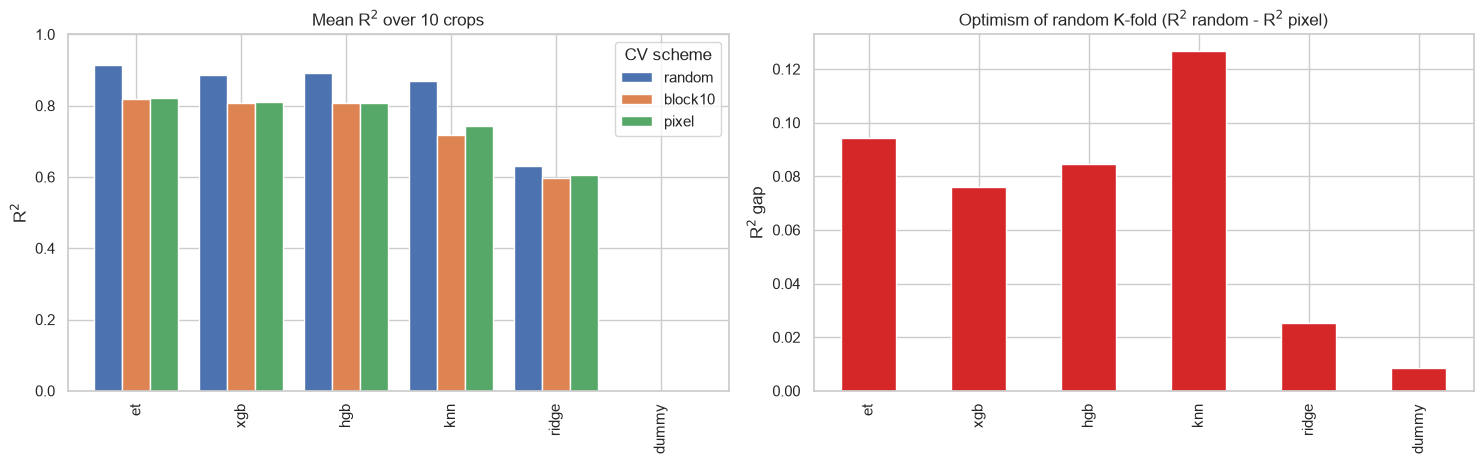

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
board[SCHEMES].plot.bar(ax=axes[0], width=0.8)
axes[0].set(title="Mean R$^2$ over 10 crops", ylabel="R$^2$", xlabel="")
axes[0].set_ylim(0, 1)
axes[0].legend(title="CV scheme")
board["leakage_gap"].plot.bar(ax=axes[1], color="tab:red")
axes[1].set(title="Optimism of random K-fold (R$^2$ random - R$^2$ pixel)", ylabel="R$^2$ gap", xlabel="")
plt.tight_layout()
E.save_fig(fig, "m01_leaderboard")
plt.show()

## 3. Per crop, honest scheme (`pixel`)

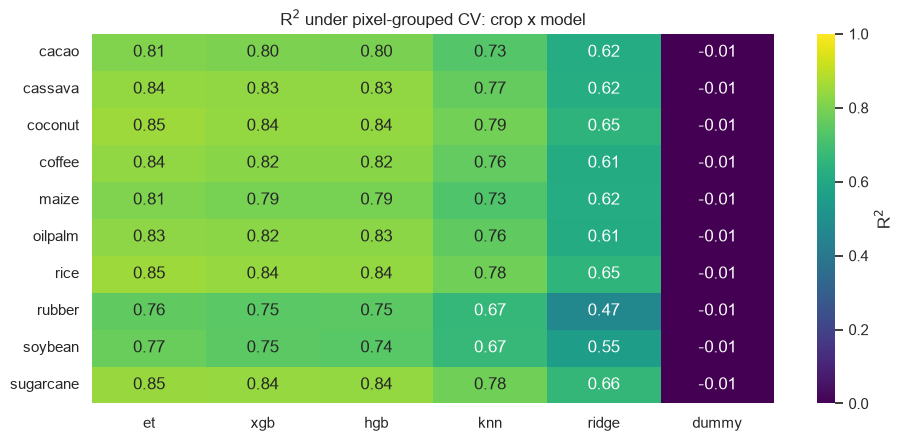

model,et,xgb,hgb,knn,ridge,dummy
target,,,,,,
cacao,0.811,0.804,0.801,0.731,0.616,-0.008
cassava,0.839,0.833,0.834,0.765,0.618,-0.008
coconut,0.852,0.837,0.837,0.787,0.647,-0.010
coffee,0.835,0.821,0.824,0.761,0.611,-0.007
maize,0.808,0.795,0.794,0.726,0.616,-0.010
oilpalm,0.830,0.824,0.826,0.755,0.611,-0.009
rice,0.852,0.842,0.840,0.783,0.649,-0.010
rubber,0.756,0.746,0.747,0.666,0.466,-0.006
soybean,0.771,0.747,0.740,0.672,0.554,-0.007


In [6]:
px = res[res["scheme"] == "pixel"].groupby(["target", "model"])["r2"].mean().unstack("model")
order = board.index.tolist()
px = px[order]
fig, ax = plt.subplots(figsize=(11, 4.8))
sns.heatmap(px, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "R$^2$"})
ax.set(title="R$^2$ under pixel-grouped CV: crop x model", xlabel="", ylabel="")
E.save_fig(fig, "m01_crop_by_model_pixel")
plt.show()
px.round(3)

In [7]:
# Average rank of each model across the 10 crops (rank 1 = best) under the honest scheme.
ranks = px.rank(axis=1, ascending=False).mean().sort_values()
rmse = (res[res["scheme"] == "pixel"].groupby("model")["rmse"].mean()).reindex(ranks.index)
spear = (res[res["scheme"] == "pixel"].groupby("model")["spearman"].mean()).reindex(ranks.index)
secs = res.groupby("model")["fit_seconds"].mean().reindex(ranks.index)
summary = pd.DataFrame({"avg_rank": ranks, "r2": px.mean().reindex(ranks.index), "rmse": rmse, "spearman": spear,
                        "fit_s_per_5folds": secs})
E.save_table(summary.round(4), "m01_summary_pixel", index=True)
summary.round(3)

,avg_rank,r2,rmse,spearman,fit_s_per_5folds
model,,,,,
et,1.0,0.820,873.097,0.902,5.079
xgb,2.4,0.809,899.596,0.896,0.958
hgb,2.6,0.808,901.159,0.897,1.040
knn,4.0,0.743,1046.874,0.864,0.099
ridge,5.0,0.605,1309.223,0.776,0.100
dummy,6.0,-0.009,2127.225,-0.111,0.003


## 4. How much of each crop's variance lies inside a ~9 km pixel?
At 1 km the target also varies inside the ~9 km pixels, so the honest `pixel` scheme scores the models on local detail
as well; `within_pixel_share` is the part of the variance that no ~9 km product could show.

In [8]:
rows = []
for c in E.CROPS:
    y = df[E.target_col(c)]
    within = (y - y.groupby(df["pix"]).transform("mean")).var()
    rows.append({"crop": c, "variance": y.var(), "within_pixel_share": within / y.var(),
                 "best_pixel_r2": px.loc[c].max(), "best_model": px.loc[c].idxmax()})
ceil = pd.DataFrame(rows).set_index("crop")
E.save_table(ceil.round(4), "m01_ceiling", index=True)
ceil.round(3)

,variance,within_pixel_share,best_pixel_r2,best_model
crop,,,,
rice,6.059946e+06,0.181,0.852,et
maize,1.014791e+06,0.200,0.808,et
cassava,7.519389e+06,0.222,0.839,et
soybean,1.886994e+06,0.234,0.771,et
oilpalm,7.693816e+06,0.248,0.830,et
rubber,8.341532e+05,0.317,0.756,et
sugarcane,3.102749e+06,0.203,0.847,et
coffee,7.776564e+06,0.206,0.835,et
cacao,4.425139e+06,0.256,0.811,et


## 5. Save out-of-fold predictions for later experiments
Mean over the two repeats, honest `pixel` scheme, tree models only.

In [9]:
KEEP = ["et", "hgb", "xgb"]
oof_df = df[["grid_id"]].copy()
for m in KEEP:
    for c in E.CROPS:
        oof_df[f"{m}__{c}"] = np.mean([oof[(m, c, "pixel", r)] for r in range(2)], axis=0)
print(E.save_oof(oof_df, "m01_oof_pixel"))
oof_df.shape

D:\Softwares\AnacondaProjects\GeoSuitability_AI_Analytics\datasets\processed\experiments\m01_oof_pixel.parquet


(9129, 31)